# `Astropy` models and fitting
If you need to do least square fitting for data to a model a good place to start is `astropy`'s modeling and fitting code.

## Packages being used
+ `astropy`: for modeling and fitting
+ `matplotlib`: for plotting

## Relevant documentation
+ `astropy`: http://docs.astropy.org/en/stable/modeling/index.html

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.modeling import models, fitting
import sys
import importlib
import subprocess
from pathlib import Path

_REPO_ROOT = Path.cwd().resolve()
while _REPO_ROOT != _REPO_ROOT.parent and not (_REPO_ROOT / 'utils' / 'mpl_style.py').exists():
    _REPO_ROOT = _REPO_ROOT.parent
if str(_REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(_REPO_ROOT))

try:
    importlib.import_module('scipy')
except ModuleNotFoundError:
    print('Installing SciPy for astropy.modeling demos...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'scipy', '--quiet'])

from utils import mpl_style
%matplotlib inline
plt.style.use(mpl_style.style1)

## 1-D model fitting
For an example lets look at the problem of fitting a 1-D model to a spectral line.  First we need to create some fake data:

In [11]:
x = np.linspace(-5., 5., 200)
y = 3 * np.exp(-0.5 * (x - 1.3)**2 / 0.8**2)
y += np.random.normal(0., 0.2, x.shape)

### A trapezoid model

In [12]:
t_init = models.Trapezoid1D(amplitude=1.0, x_0=0.1, slope=0.5)
fit_t = fitting.LevMarLSQFitter()
t = fit_t(t_init, x, y)
print(t)

Model: Trapezoid1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude             x_0               width              slope       
    ------------------ ------------------ ------------------ ------------------
    3.0602803838767842 1.2787475945348727 0.2907784704698928 1.8667015786130126


### A Gaussian model

In [13]:
g_init = models.Gaussian1D(amplitude=1., mean=0, stddev=1.)
fit_g = fitting.LevMarLSQFitter()
g = fit_g(g_init, x, y)
print(g)

Model: Gaussian1D
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Parameters:
        amplitude             mean              stddev      
    ------------------ ------------------ ------------------
    3.0277296636834965 1.2764447572216315 0.8010228325454594


### Plotting the results

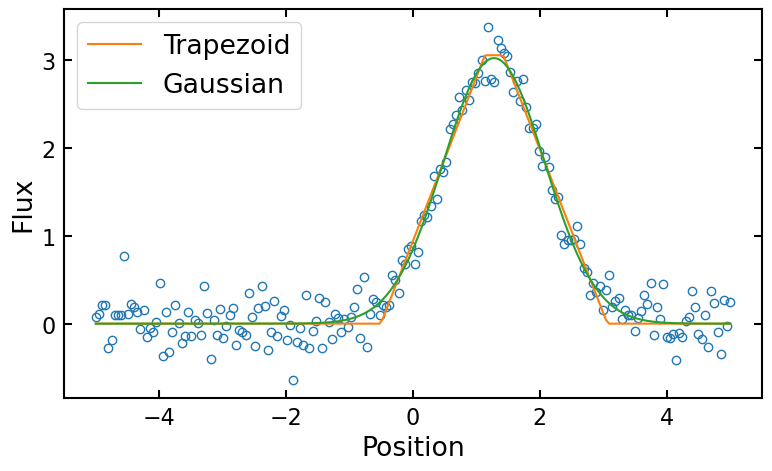

In [14]:
plt.figure(1, figsize=(8,5))
plt.plot(x, y, 'o', mfc='none')
plt.plot(x, t(x), label='Trapezoid')
plt.plot(x, g(x), label='Gaussian')
plt.xlabel('Position')
plt.ylabel('Flux')
plt.legend(loc=2)
plt.tight_layout()

## Compound models
Models can also be 'added' together before fitting.  To demonstrate lets make a new dataset made up to two Gaussians.

In [15]:
np.random.seed(42)
g1 = models.Gaussian1D(1, 0, 0.2)
g2 = models.Gaussian1D(2.5, 0.5, 0.1)
x = np.linspace(-1, 1, 200)
y = g1(x) + g2(x) + np.random.normal(0., 0.2, x.shape)

### Make the model
The model can be 'added' just like arrays:

In [16]:
gg_init = models.Gaussian1D(1, 0, 0.1) + models.Gaussian1D(2, 0.5, 0.1)
fit_gg = fitting.SLSQPLSQFitter()
gg = fit_gg(gg_init, x, y)
print(gg)

Optimization terminated successfully    (Exit mode 0)
            Current function value: 6.832859352651455
            Iterations: 15
            Function evaluations: 128
            Gradient evaluations: 15
Model: CompoundModel
Inputs: ('x',)
Outputs: ('y',)
Model set size: 1
Expression: [0] + [1]
Components: 
    [0]: <Gaussian1D(amplitude=0.98118974, mean=0.00597661, stddev=0.20738563)>

    [1]: <Gaussian1D(amplitude=2.48566492, mean=0.5041208, stddev=0.10000035)>
Parameters:
       amplitude_0            mean_0        ...       stddev_1     
    ------------------ -------------------- ... -------------------
    0.9811897370415261 0.005976607013072679 ... 0.10000035331642167


/Users/xangma/miniconda3/envs/ai/lib/python3.13/site-packages/scipy/optimize/_slsqp_py.py:435: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  fx = wrapped_fun(x)


### Plot the result

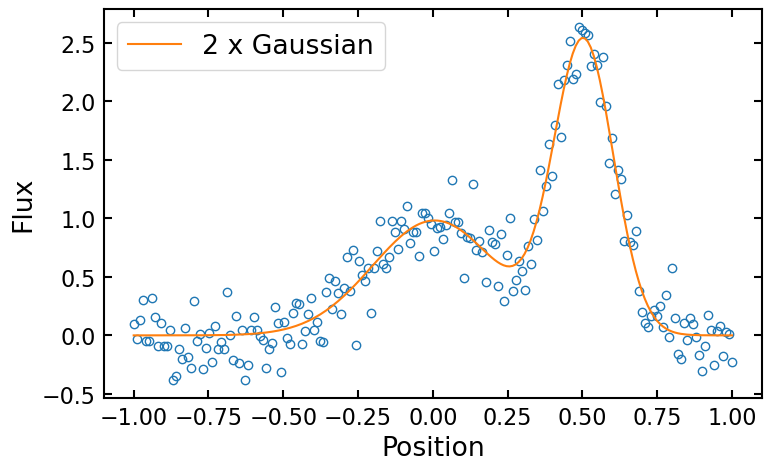

In [17]:
plt.figure(2, figsize=(8, 5))
plt.plot(x, y, 'o', mfc='none')
plt.plot(x, gg(x), label='2 x Gaussian')
plt.xlabel('Position')
plt.ylabel('Flux')
plt.legend(loc=2)
plt.tight_layout()

## `Astropy`'s models
`Astropy` has a large number of 1- and 2-D models built in.  Check out https://docs.astropy.org/en/stable/modeling/index.html#module-astropy.modeling.functional_models for a full list.  If the model you are looking for is not built in, you can always define your own: https://docs.astropy.org/en/stable/modeling/new-model.html.

## Limitations
+ Uses OLS (or similar) to maximize an objective function (and all the assumptions about the data that go into this, e.g. Gaussian errors)
+ Cov of fit only returned for some fitters (fond on the `fitter.fit_info()` method)

## Saving Figures
Use `plt.savefig` to store publication-quality graphics. Set a high `dpi` (e.g., 300) for PNG output and also write a PDF when you need vector graphics for journals. The snippet below makes sure an `images/` folder exists before saving both formats.

In [18]:
from pathlib import Path

demo_fig, demo_ax = plt.subplots(figsize=(4, 3))
x_demo = np.linspace(0, 2 * np.pi, 200)
demo_ax.plot(x_demo, np.sin(x_demo), label='demo')
demo_ax.set_xlabel('x')
demo_ax.set_ylabel('sin(x)')
demo_ax.legend(loc='best')
search_root = Path.cwd().resolve()
images_dir = None
while True:
    candidate = search_root / 'images'
    if candidate.exists():
        images_dir = candidate
    if search_root == search_root.parent:
        break
    search_root = search_root.parent
if images_dir is None:
    images_dir = Path.cwd().resolve() / 'images'
images_dir.mkdir(parents=True, exist_ok=True)
png_path = images_dir / 'class2_astropy_fitting_demo.png'
pdf_path = images_dir / 'class2_astropy_fitting_demo.pdf'
demo_fig.savefig(png_path, dpi=300)
demo_fig.savefig(pdf_path)
plt.close(demo_fig)
print(f"Saved {png_path} and {pdf_path}")

Saved /Users/xangma/Library/CloudStorage/OneDrive-Personal/repos/jupyter_data_languages/images/class2_astropy_fitting_demo.png and /Users/xangma/Library/CloudStorage/OneDrive-Personal/repos/jupyter_data_languages/images/class2_astropy_fitting_demo.pdf
